In [7]:
import pandas as pd

file_path = "student_dance_1.csv"

df_student = pd.read_csv(file_path)
df_student.head()

,Frame,Timestamp,Joint_Name,X,Y,Z,Visibility,Label
0,0,0.0,nose,NaN,NaN,NaN,0.0,1
1,0,0.0,left_shoulder,NaN,NaN,NaN,0.0,1
2,0,0.0,right_shoulder,NaN,NaN,NaN,0.0,1
3,0,0.0,left_elbow,NaN,NaN,NaN,0.0,1
4,0,0.0,right_elbow,NaN,NaN,NaN,0.0,1


Kiểm định Nội suy - Trục X | RMSE: 0.0238 | MAE: 0.0112


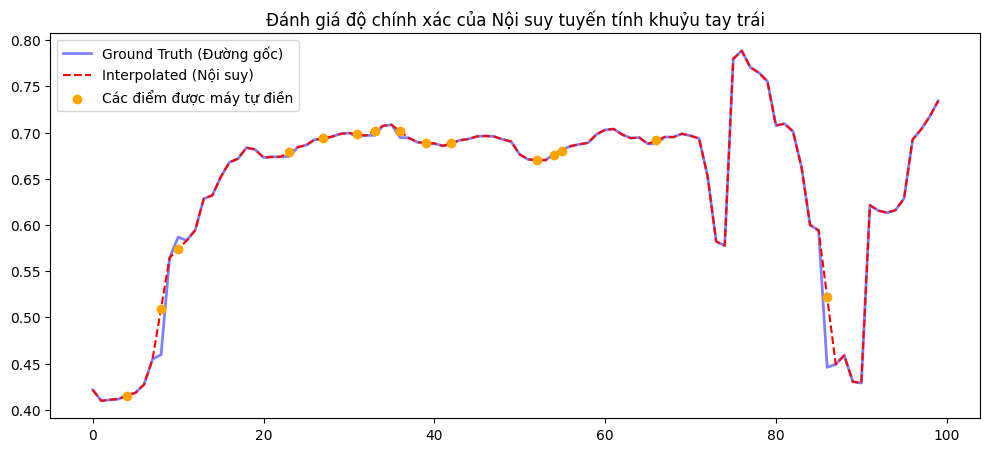

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Giả lập/Tải dữ liệu Ground Truth (Frame 1 -> 100, Visibility > 0.95)
# Ở đây tớ lấy DataFrame df_student đã load trước đó
df_clean = df_student[(df_student['Joint_Name'] == 'left_elbow') & (df_student['Visibility'] > 0.95)].copy()
df_clean = df_clean.head(100).reset_index(drop=True) # Lấy 100 frames liên tục

# Lưu lại đáp án chuẩn
df_clean['X_original'] = df_clean['X']

# 2. Xóa giả lập (Random 15% frames bị mất dấu)
mask_indices = np.random.choice(df_clean.index, size=15, replace=False)
df_clean.loc[mask_indices, 'X'] = np.nan 

# 3. Chạy thuật toán nội suy tuyến tính
df_clean['X_interpolated'] = df_clean['X'].interpolate(method='linear')

# 4. Tính toán sai số (Chỉ tính trên các điểm bị xóa)
missing_only = df_clean.loc[mask_indices]
rmse = np.sqrt(((missing_only['X_original'] - missing_only['X_interpolated']) ** 2).mean())
mae = (missing_only['X_original'] - missing_only['X_interpolated']).abs().mean()

print(f"Kiểm định Nội suy - Trục X | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

# 5. Trực quan hóa
plt.figure(figsize=(12, 5))
plt.plot(df_clean.index, df_clean['X_original'], label='Ground Truth (Đường gốc)', color='blue', alpha=0.5, linewidth=2)
plt.plot(df_clean.index, df_clean['X_interpolated'], label='Interpolated (Nội suy)', color='red', linestyle='dashed')
plt.scatter(mask_indices, df_clean.loc[mask_indices, 'X_interpolated'], color='orange', label='Các điểm được máy tự điền', zorder=5)
plt.title("Đánh giá độ chính xác của Nội suy tuyến tính khuỷu tay trái")
plt.legend()
plt.show()

Kiểm định Nội suy - Trục X | RMSE: 0.0178 | MAE: 0.0120


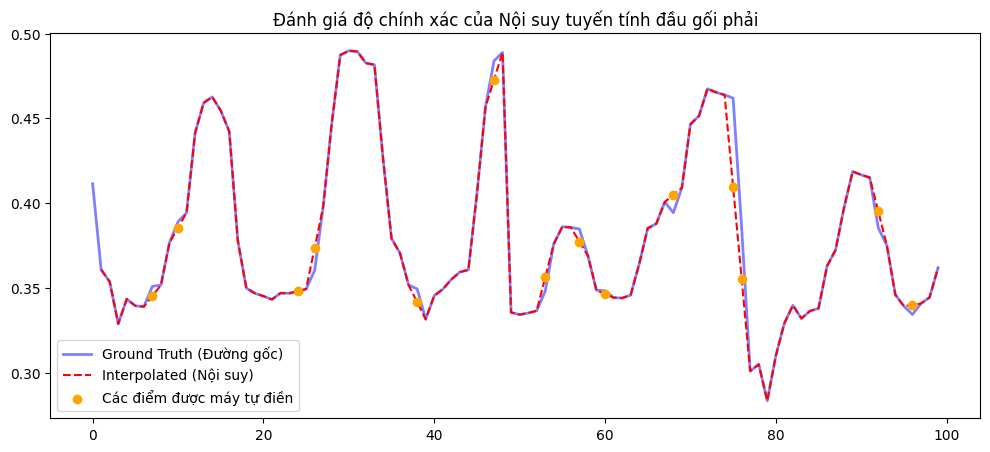

In [9]:

df_clean = df_student[(df_student['Joint_Name'] == 'right_knee') & (df_student['Visibility'] > 0.95)].copy()
df_clean = df_clean.head(100).reset_index(drop=True) # Lấy 100 frames liên tục

# Lưu lại đáp án chuẩn
df_clean['X_original'] = df_clean['X']

# 2. Xóa giả lập (Random 15% frames bị mất dấu)
mask_indices = np.random.choice(df_clean.index, size=15, replace=False)
df_clean.loc[mask_indices, 'X'] = np.nan 

# 3. Chạy thuật toán nội suy tuyến tính
df_clean['X_interpolated'] = df_clean['X'].interpolate(method='linear')

# 4. Tính toán sai số (Chỉ tính trên các điểm bị xóa)
missing_only = df_clean.loc[mask_indices]
rmse = np.sqrt(((missing_only['X_original'] - missing_only['X_interpolated']) ** 2).mean())
mae = (missing_only['X_original'] - missing_only['X_interpolated']).abs().mean()

print(f"Kiểm định Nội suy - Trục X | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

# 5. Trực quan hóa
plt.figure(figsize=(12, 5))
plt.plot(df_clean.index, df_clean['X_original'], label='Ground Truth (Đường gốc)', color='blue', alpha=0.5, linewidth=2)
plt.plot(df_clean.index, df_clean['X_interpolated'], label='Interpolated (Nội suy)', color='red', linestyle='dashed')
plt.scatter(mask_indices, df_clean.loc[mask_indices, 'X_interpolated'], color='orange', label='Các điểm được máy tự điền', zorder=5)
plt.title("Đánh giá độ chính xác của Nội suy tuyến tính đầu gối phải")
plt.legend()
plt.show()